In [145]:
#Import libraries and define Symbols
import sympy as smp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, RK45, BDF
from scipy.optimize import direct, Bounds
import scipy as sp
import time
import random
import math
from control import lqr, lqe

## Parameters

$C_D$ - Coefficient of Drag 

$C_L$ - Coefficient of Lift 

$S$ - Reference Area 

$I_{yy}$ - Pitching Moment

$T$ - Thrust curve (to be turned into function of time)

$m$ - Mass of rocket (to be turned into function of time)

$g$ - Acceleration due to gravity

$d_{CoP}$ - Distance from CoM to Center of Pressure

$d_{Noz}$ - Distance from CoM to Nozzle

$\rho$ - Density of air

In [64]:
#Parameters

Cd = 0.1
Cl = 0.01
S = 0.01

Iyy = 0.2705

T = 100
m = 7
g = 9.8
dCoP = 0.5
dNoz = 0.7
rho = 1.225

## Ascent Control Matrices

out of date

$$
A = \begin{bmatrix}
0 & 1 & 0& 0\\
0 & -\frac{\rho S C_D}{2m} |\dot{z}|& -\frac{T}{m}&0 \\
0 & 0& 0& 1\\
0 &\frac{\rho S C_D d_{CoP}}{2 I_{yy}} |\dot{z}| & -\frac{\rho S C_D d_{CoP}}{2 I_{yy}} |\dot{z}| \dot{z}& 0\\
\end{bmatrix}

\\

B = \begin{bmatrix}
0 & 0\\
-\frac{T}{m} &0 \\
0 & 0\\
\frac{d_{Noz}T}{I_{yy}} & 0\\
\end{bmatrix}
$$

In [ ]:
#Ascent Control matrices
def A(t, dz):
    a = np.zeros([6,6])
    a[0,2] = 1
    a[1,3] = 1
    a[2,4] = -g
    a[3,3] = -(rho*S*Cd)/(2*m) * np.abs(dz)
    # a[4,4] = -g / dz if dz != 0 else 0
    a[4,5] = 1
    a[5,2] = (rho*S*Cd*dCoP)/(2*Iyy) * np.abs(dz)
    a[5,4] = -(rho*S*Cd*dCoP)/(2*Iyy) * np.abs(dz) * dz
    return a
print(A(0, 0).round(3))
def B(t, dz):
    b = np.zeros([6,2])
    b[2,0] = -g
    b[3,1] = -T/m
    b[5,0] = dNoz*m*g/Iyy
    return b
print(B(0, 0))

[[ 0.   0.   1.   0.   0.   0. ]
 [ 0.   0.   0.   1.   0.   0. ]
 [ 0.   0.   0.   0.  -9.8  0. ]
 [ 0.   0.   0.  -0.   0.   0. ]
 [ 0.   0.   0.   0.   0.   1. ]
 [ 0.   0.   0.   0.  -0.   0. ]]
[[  0.      0.   ]
 [  0.      0.   ]
 [ -9.8     0.   ]
 [  0.    -14.286]
 [  0.      0.   ]
 [177.523   0.   ]]


In [130]:
def A_full_linearized(x, u):
    a = np.zeros([6, 6])
    a[0,2] = 1
    a[3,1] = -g / x[1]
    a[1,3] = 1
    a[2,2] = (-rho*S*Cd/2*m) * math.sqrt(x[2] * x[2] + x[3] * x[3])
    a[3,3] = (-rho*S*Cd/2*m) * math.sqrt(x[2] * x[2] + x[3] * x[3])
    a[4,5] = 1
    a[5,2] = (-rho*S*Cd*dCoP/2*Iyy) *  math.sqrt(x[2] * x[2] + x[3] * x[3]) * math.cos(x[4])
    a[5,3] = (-rho*S*Cd*dCoP/2*Iyy) * -math.sqrt(x[2] * x[2] + x[3] * x[3]) * math.sin(x[4])
    return a

# u [gamma T(1-P)]
def B_full_linearized(x, u):
    b = np.zeros([6, 2])
    b[2,1] = -math.sin(x[4] + u[0]) / m
    b[3,1] = math.cos(x[4] + u[0]) / m
    # sin(gamma) ~= gamma
    b[5,0] = u[1] * dNoz / Iyy
    return b


## Differential equation
$$

\begin{bmatrix}
    \dot{x} \\
    \dot{z} \\
    \ddot{x} \\
    \ddot{z} \\
    \dot{\theta} \\
    \ddot{\theta}
\end{bmatrix} 
= \begin{bmatrix}
    \dot{x} \\
    \dot{z} \\
    -\frac{\rho S C_D}{2m} \dot{x} \sqrt{\dot{x}^2 + \dot{z}^2} - \frac{(1-P)T}{m} \sin(\theta + \gamma)\\
    -\frac{\rho S C_D}{2m} \dot{z} \sqrt{\dot{x}^2 + \dot{z}^2} - \frac{(1-P)T}{m} \cos(\theta + \gamma)-g\\
    \dot{\theta} \\
    -\frac{\rho S C_D d_{CoP}}{2 I_{yy}} \left(\dot{x} \sqrt{\dot{x}^2 + \dot{z}^2} \cos(\theta)-\dot{z} \sqrt{\dot{x}^2 + \dot{z}^2} \sin(\theta)\right) + \frac{(1-P)T d_{Noz}}{I_{yy}} \sin(\gamma)\\
\end{bmatrix}

$$

In [164]:
#DiffEq Solver (BDF)
Q = np.diag([1,1,10,700,100,500])
R = np.diag([0.001,1])

u_t_1 = [0, 0]

def z_ref(t):
    return 100
    # if t<20:
    #     return 100
    # if t>20:
    #     return 0

def dz_ref(z,t):
    if z < 100:
        return 10
    return 0
    # if (z<100 and t<20):
        # return 10
    # elif (z>100 and t<20):
        # return 0
    # elif (z>20 and t>20):
        # return -10
    # else:
        # return 0

# Define the system of ODEs
def system(t, true_state):
    # true_state = true_state[:6]

    global kalman_states, kalman_covariances
    if len(kalman_states) == 0:
        kalman_states.append(true_state)

    x, z, dx, dz, theta, dtheta = true_state

    #LQR to find K
    At = A(t, dz)
    Bt = B(t, dz)
        
    K, Ric, Eig = lqr(At, Bt, Q, R)

    #Set control parameters
    gamma, P = -K @ [x, z-z_ref(t), dx, dz-dz_ref(z,t), theta, dtheta]
    

    #Max control speed
    '''
    if len(t_vals) > 0:
        dt = t-t_vals[-1]
        dP = P-P_vals[-1]
        P_maxrate = 100000
        P = P_vals[-1] + np.clip(dP/dt, 0,P_maxrate) * dt
    '''

    #Max Control magnitude
    b=100.0
    global dPdt
    dP=0
    dt=1
    if len(t_vals) > 0:
        dt = t-t_vals[-1]
        dP = P-P_vals[-1]
        P = P_vals[-1] + (dP/dt)*dt /b
    if P>1:
        dPdt = 0
    else:
        dPdt=dP/dt

    P = np.clip(P,0,1)
    gamma = np.clip(gamma, -np.pi/2, np.pi/2)
    
    
    #No Control
    #gamma = 0
    #P = 0

    global u_t_1
    u_t_1 = [gamma, P]

    ddx = -(rho*S*Cd)/(2*m) * dx * np.sqrt(dx**2 + dz**2) - (1-P)*T/m * np.sin(theta + gamma)
    ddz = -(rho*S*Cd)/(2*m) * dz * np.sqrt(dx**2 + dz**2) + (1-P)*T/m * np.cos(theta + gamma) - g
    ddtheta = (rho*S*Cd*dCoP)/(2*Iyy) * (dx *  np.sqrt(dx**2 + dz**2) * np.cos(theta) - dz *  np.sqrt(dx**2 + dz**2) * np.sin(theta)) + (1-P)*dNoz*T/Iyy * np.sin(gamma)
    return [dx, dz, ddx, ddz, dtheta, ddtheta]

# Initial conditions
initial_state = [0,1,0,0.1,0.1,0.0]

# Time span
t_span = (0, 20.0)

#Solution Data
t_vals, State_vals, gamma_vals, P_vals = [], [], [], []
dPdt_vals = []


#End status (0=full run, 1=took too long, 2=crashed)
status = 0

# kalman filter
C = np.identity(6)
D = np.zeros([6,2])
R_kalman = np.diag([1, 1, 1, 1, 1, 1]) * 1e-5
Q_kalman = np.diag([0.01, 0.01, 0.01, 0.01, 0.01, 0.01])
# multiply noise by this when used
# simulates us over/underestimating noisyness
noise_factor = 2

kalman_times = [0]
kalman_states = [np.array(initial_state)]
kalman_covariances = [np.identity(6)*0.001]
kalman_covariances[0] [0][2] = 0.001
kalman_covariances[0] [2][0] = 0.001

kalman_covariances[0] [1][3] = 0.001
kalman_covariances[0] [3][1] = 0.001

kalman_covariances[0] [4][5] = 0.001
kalman_covariances[0] [5][4] = 0.001
t_1 = 0

#Start Solver
start_time = time.time()
solver = BDF(system, t_span[0], initial_state, t_span[1])
while solver.status == "running":
    #Step solver and save data
    solver.step()
    t_vals.append(solver.t)
    State_vals.append(solver.y.copy())
    gamma_vals.append(u_t_1[0])
    P_vals.append(u_t_1[1])
    dPdt_vals.append(dPdt)

    # kalman filter
    if (solver.t - t_1 > 0.1):
        Q_d = np.identity(Q_kalman.shape[0]) + Q_kalman * (solver.t - t_1)
        R_d = R_kalman / (solver.t - t_1)
        observed_state = solver.y
        v = np.random.standard_normal(6)
        observed_state += R_d@v * noise_factor
        u_linear = [u_t_1[0], (1 - u_t_1[1]) * T]
        Atc = A_full_linearized(solver.y, u_linear)
        Btc = B_full_linearized(solver.y, u_linear)
        Atd = sp.linalg.expm(Atc * (solver.t - t_1))
        Btd = np.linalg.pinv(Atc)@(Atd - np.identity(6))@Btc
        
        w = np.random.standard_normal(6)
        apriori_state = Atd@kalman_states[-1] + Btd@u_linear + Q_d@w * noise_factor
        # print("apriori")
        # print(apriori_state)
        # print(observed_state - C@apriori_state - D@u_t_1)
        apriori_covariance = Atd@kalman_covariances[-1]@Atd.T + Q_d
        kalman_gain = np.linalg.inv(apriori_covariance) @np.transpose(C) @np.linalg.inv(C@apriori_covariance@np.transpose(C) + R_d)
        # kalman_gain, _, _ = lqe(Atd, np.identity(6), C, Q_d, R_d)
        # print(kalman_gain.round(3))
        # print(kalman_gain)
        # i cant decide if "aposteriori" sounds cool or dumb 
        aposteriori_state = apriori_state + kalman_gain@(observed_state - C@apriori_state - D@u_linear)
        kalman_states.append(aposteriori_state)
        aposteriori_covariance = (np.identity(6) - kalman_gain@C)@apriori_covariance@(np.identity(6) - kalman_gain@C).T + kalman_gain@R_d@kalman_gain.T
        kalman_covariances.append(aposteriori_covariance)
        kalman_times.append(solver.t)

        t_1 = solver.t

    #End conditions
    if time.time() - start_time > 10:   
        solver.status = "stopped"       
        status = 1
        break
    if (State_vals[-1][1] < 0):
        solver.status = "stopped"    
        status = 2
        break

print("\nfinal data")
#Timestamped data
State_vals = np.array(State_vals).T
print(kalman_states)
kalman_states = np.array(kalman_states).T
print(max(dPdt_vals))
print(kalman_states)


final data
[array([0. , 1. , 0. , 0.1, 0.1, 0. ]), array([-0.011,  1.033, -0.135,  0.552,  0.096, -0.076]), array([-0.033,  1.121, -0.267,  1.025,  0.077, -0.123]), array([-0.067,  1.255, -0.397,  1.53 ,  0.072, -0.156]), array([-0.124,  1.49 , -0.502,  2.088,  0.055, -0.158]), array([-0.23 ,  2.083, -0.602,  3.1  ,  0.015, -0.177]), array([-0.341,  2.66 , -0.587,  3.865, -0.02 , -0.134]), array([-0.436,  3.293, -0.53 ,  4.522, -0.042, -0.111]), array([-0.547,  4.536, -0.377,  5.633, -0.056, -0.046]), array([-0.614,  5.571, -0.244,  6.393, -0.056, -0.014]), array([-0.632,  6.717, -0.11 ,  7.142, -0.045,  0.014]), array([-0.643,  8.262,  0.047,  8.057, -0.044,  0.04 ]), array([-0.633,  9.261,  0.138,  8.587, -0.047,  0.048]), array([-0.607, 10.319,  0.213,  9.121, -0.043,  0.068]), array([-0.573, 11.453,  0.278,  9.668, -0.032,  0.078]), array([-0.547, 12.638,  0.324, 10.189, -0.025,  0.066]), array([-4.891e-01,  1.455e+01,  3.673e-01,  1.098e+01, -7.210e-03,
        8.155e-02]), array

Status: 0


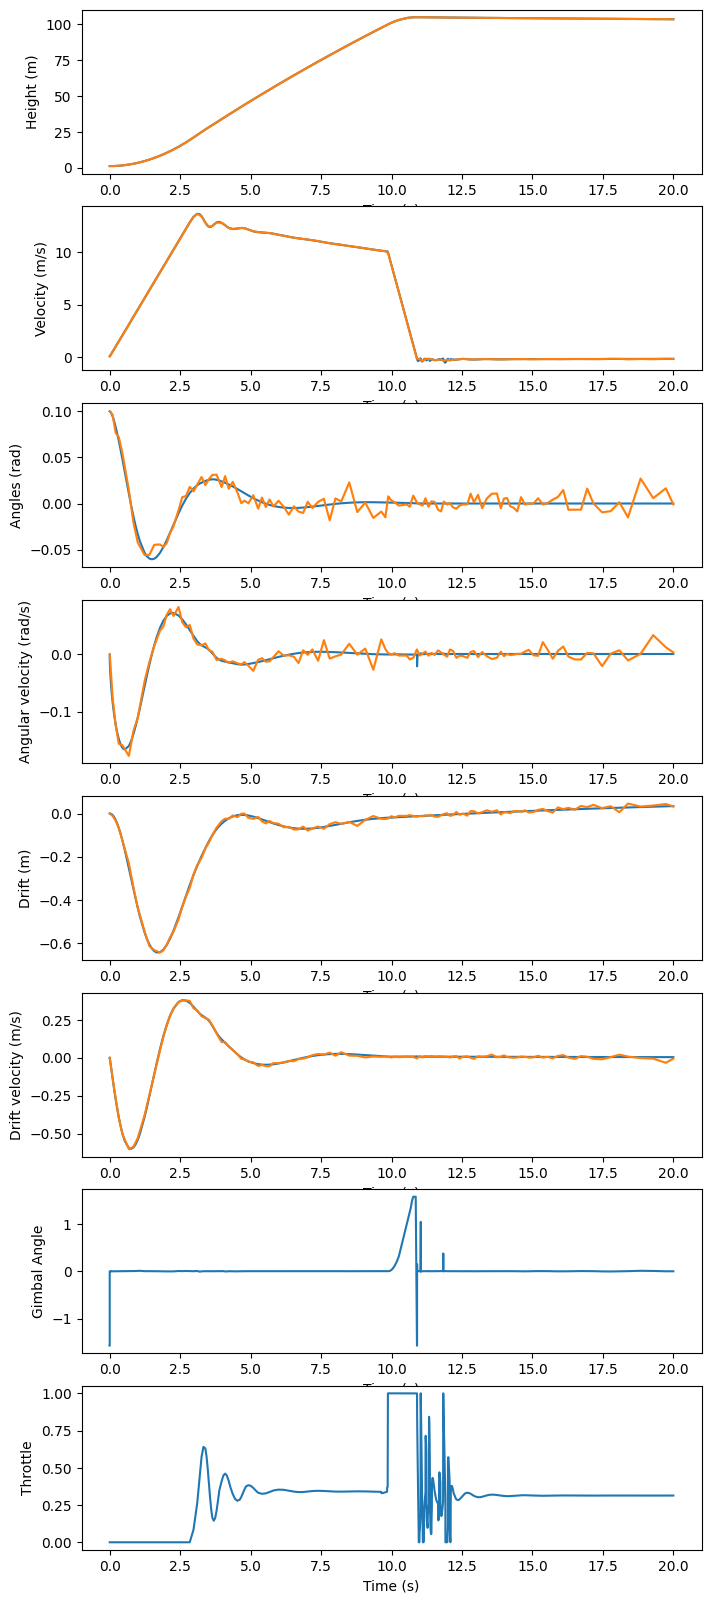

In [165]:
#Plot the trajectory
fig, ax = plt.subplots(nrows=6 + 2, ncols=1,figsize=(8, 20))
for i in range(6 + 2):
    ax[i].set_xlabel("Time (s)")

def plot_noisy_value(ax, ts, vals, noises):
    # pass
    ax.plot(ts, vals)
    # ax.scatter(ts, vals)
    ax.fill_between(ts, vals - noises, vals + noises, alpha = 0.2, color="orange")

ax[0].plot(t_vals, State_vals[1])
plot_noisy_value(ax[0], kalman_times, kalman_states[1], [c[1, 1] for c in kalman_covariances])
ax[1].plot(t_vals, State_vals[3])
plot_noisy_value(ax[1], kalman_times, kalman_states[3], [c[3, 3] for c in kalman_covariances])
ax[2].plot(t_vals, State_vals[4])
plot_noisy_value(ax[2], kalman_times, kalman_states[4], [c[4, 4] for c in kalman_covariances])
ax[3].plot(t_vals, State_vals[5])
plot_noisy_value(ax[3], kalman_times, kalman_states[5], [c[5, 5] for c in kalman_covariances])
ax[4].plot(t_vals, State_vals[0])
plot_noisy_value(ax[4], kalman_times, kalman_states[0], [c[0, 0] for c in kalman_covariances])
ax[5].plot(t_vals, State_vals[2])
plot_noisy_value(ax[5], kalman_times, kalman_states[2], [c[2, 2] for c in kalman_covariances])
ax[6].plot(t_vals, gamma_vals)
ax[7].plot(t_vals, P_vals)

ax[0].set_ylabel("Height (m)")
ax[1].set_ylabel("Velocity (m/s)")
ax[2].set_ylabel("Angles (rad)")
ax[3].set_ylabel("Angular velocity (rad/s)")
ax[4].set_ylabel("Drift (m)")
ax[5].set_ylabel("Drift velocity (m/s)")
ax[6].set_ylabel("Gimbal Angle")
ax[7].set_ylabel("Throttle")

#Print status (0=full run, 1=took too long, 2=crashed)
print(f"Status: {status}")

#Show plots
plt.show() # type: ignore

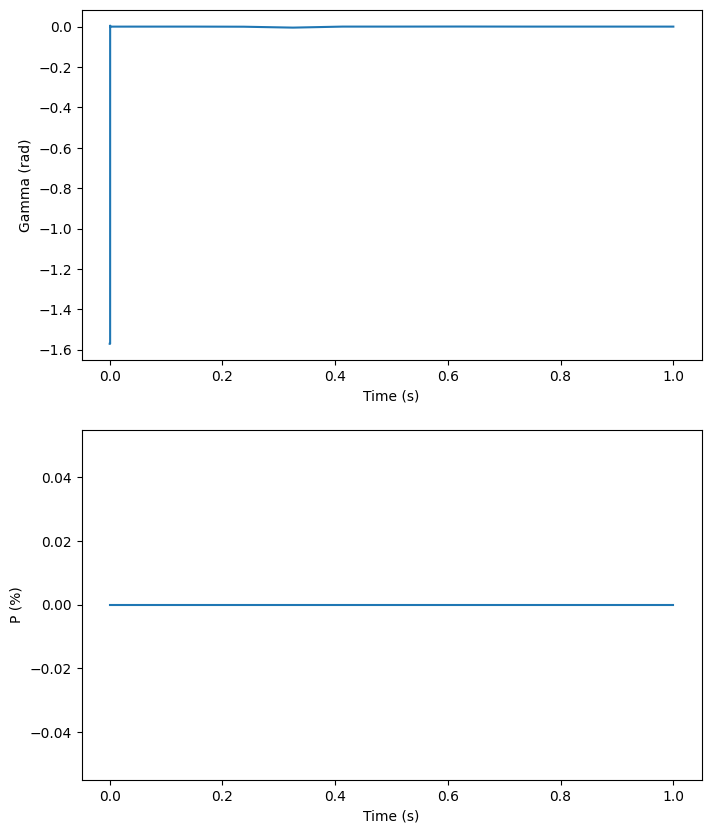

In [68]:
#Plot the control
fig, ax = plt.subplots(nrows=2, ncols=1,figsize=(8, 10))

ax[0].set_xlabel("Time (s)")
ax[1].set_xlabel("Time (s)")

ax[0].plot(t_vals, gamma_vals)
ax[1].plot(t_vals, P_vals)


ax[0].set_ylabel("Gamma (rad)")
ax[1].set_ylabel("P (%)")

#Show plots
plt.show()